<a href="https://colab.research.google.com/github/192565074simats-code/MLA0201/blob/main/Experiment_15.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

IRIS FLOWER DATASET
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   
5                5.4               3.9                1.7               0.4   
6                4.6               3.4                1.4               0.3   
7                5.0               3.4                1.5               0.2   
8                4.4               2.9                1.4               0.2   
9                4.9               3.1                1.5               0.1   

  Species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  
5  setosa  
6  setosa  
7  setosa  
8 

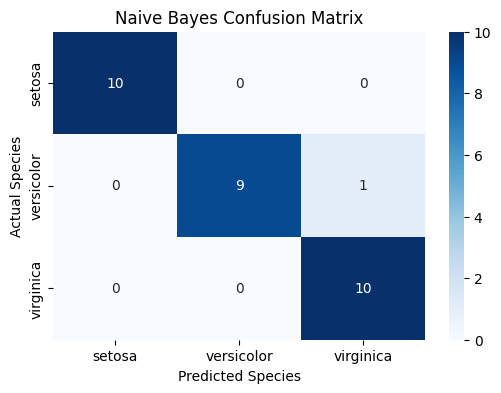

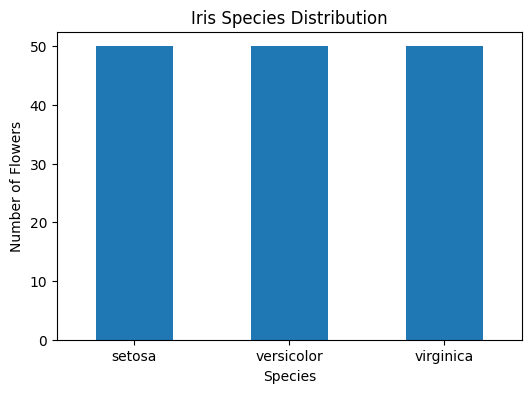

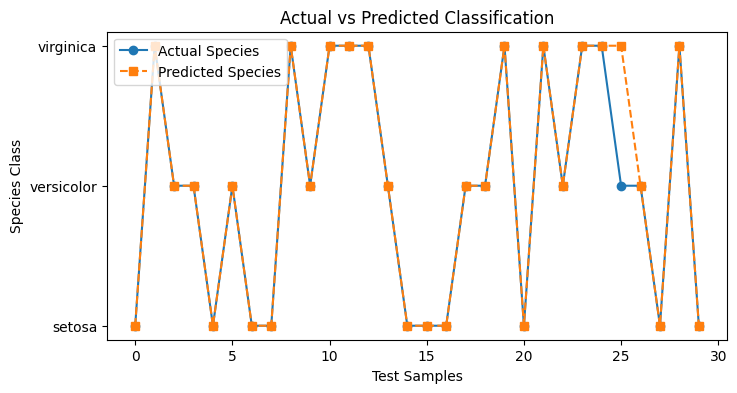

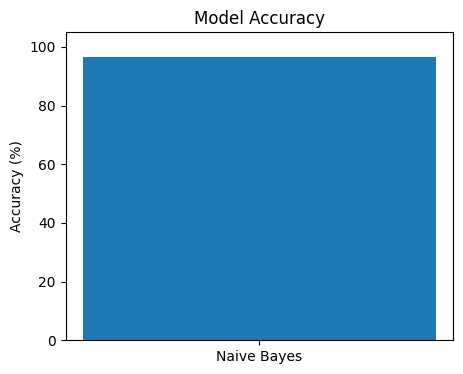


NEW FLOWER DETAILS
Sepal Length: 5.1
Sepal Width: 3.5
Petal Length: 1.4
Petal Width: 0.2

Predicted Flower Species: setosa


In [1]:
# EXPERIMENT 15: IRIS CLASSIFICATION USING NAIVE BAYES

# Step 1: Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Step 2: Load Iris dataset
iris = load_iris()

X = iris.data
y = iris.target

df = pd.DataFrame(X, columns=iris.feature_names)
df['Species'] = [iris.target_names[i] for i in y]

print("IRIS FLOWER DATASET")
print(df.head(10))

print("\nDataset Shape:", df.shape)

# Step 3: Split training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))

# Step 4: Train Naive Bayes model
model = GaussianNB()

model.fit(X_train, y_train)

print("\nNaive Bayes Model Trained Successfully!")

# Step 5: Predict flower species
y_pred = model.predict(X_test)

results = pd.DataFrame({
    'Actual Species': iris.target_names[y_test],
    'Predicted Species': iris.target_names[y_pred]
})

print("\nCLASSIFICATION RESULTS")
print(results)

# Step 6: Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=iris.target_names
))

# Step 7: Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("Naive Bayes Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.show()

# Step 8: Species Distribution Graph
plt.figure(figsize=(6, 4))

df['Species'].value_counts().plot(kind='bar')

plt.title("Iris Species Distribution")
plt.xlabel("Species")
plt.ylabel("Number of Flowers")
plt.xticks(rotation=0)
plt.show()

# Step 9: Actual vs Predicted Graph
plt.figure(figsize=(8, 4))

plt.plot(y_test, 'o-', label='Actual Species')
plt.plot(y_pred, 's--', label='Predicted Species')

plt.title("Actual vs Predicted Classification")
plt.xlabel("Test Samples")
plt.ylabel("Species Class")
plt.yticks([0, 1, 2], iris.target_names)
plt.legend()
plt.show()

# Step 10: Accuracy Graph
plt.figure(figsize=(5, 4))

plt.bar(['Naive Bayes'], [accuracy * 100])

plt.title("Model Accuracy")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 105)
plt.show()

# Step 11: Predict New Flower
new_flower = [[5.1, 3.5, 1.4, 0.2]]

prediction = model.predict(new_flower)

print("\nNEW FLOWER DETAILS")
print("Sepal Length: 5.1")
print("Sepal Width: 3.5")
print("Petal Length: 1.4")
print("Petal Width: 0.2")

print("\nPredicted Flower Species:",
      iris.target_names[prediction[0]])